In [1]:
import sys
import numpy as np
import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import time
print(sys.version)
print(np.__version__)
print(mp.__version__)
print(cv2.__version__)

3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)]
2.5.5
1.2.3
5.0.0


(1320, 1115, 3)


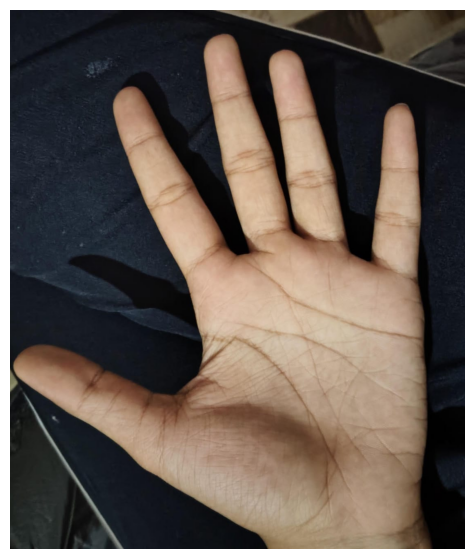

In [15]:
image=cv2.imread("hand.jpeg")
print(image.shape)
image_rgb=cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
plt.figure(figsize=(7,7))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()


In [2]:
Baseoptions=mp.tasks.BaseOptions
Handlandmarker=mp.tasks.vision.HandLandmarker
HandlandmarkerOptions=mp.tasks.vision.HandLandmarkerOptions
VisionRunningMode=mp.tasks.vision.RunningMode
options=HandlandmarkerOptions(
    base_options=Baseoptions(
        model_asset_path="hand_landmarker.task"
    ),
    running_mode=VisionRunningMode.VIDEO,
    num_hands=2
)
detector=Handlandmarker.create_from_options(options)


In [ ]:
mp_image=mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=image_rgb
)
result=detector.detect(mp_image)
total_hands=result.hand_landmarks
landmarks_in_firsthand=result.hand_landmarks[0]
print(len(total_hands))
print(len(landmarks_in_firsthand))
for i, landmark in enumerate(landmarks_in_firsthand):
    print(
        f"Landmark {i}: "
        f"x={landmark.x:.3f}, "
        f"y={landmark.y:.3f}, "
        f"z={landmark.z:.3f}"
    )

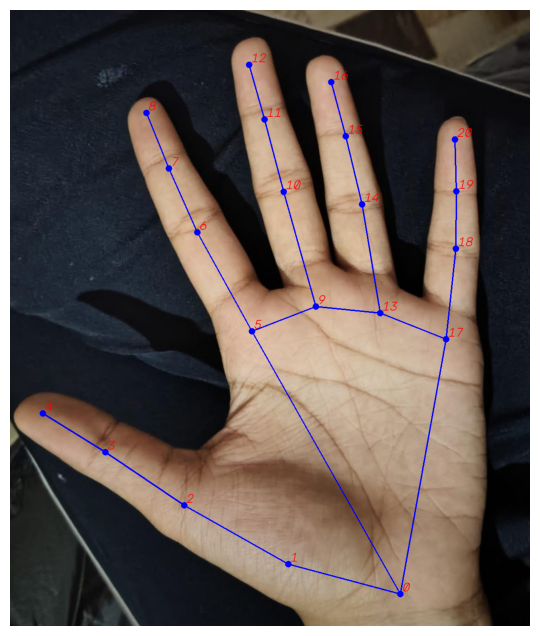

Left
0.9728131890296936


In [ ]:
height, width, _=image_rgb.shape
annotated_img=image_rgb.copy()
for i, landmark in enumerate(landmarks_in_firsthand):
    x=int(landmark.x*width)
    y=int(landmark.y*height)
    cv2.circle(annotated_img,(x,y),7,(0,0,255),-1)
    cv2.putText(
        annotated_img,
        str(i),
        (x+5,y-5),
        cv2.FONT_HERSHEY_SCRIPT_SIMPLEX,
        1,
        (255,0,0),
        1

    )
connections = [
    # Thumb
    (0,1), (1,2), (2,3), (3,4),

    # Index finger
    (0,5), (5,6), (6,7), (7,8),

    # Middle finger
    (5,9), (9,10), (10,11), (11,12),

    # Ring finger
    (9,13), (13,14), (14,15), (15,16),

    # Little finger
    (13,17), (17,18), (18,19), (19,20),

    # Palm
    (0,17)
]
for start, end in connections:
    x1=int(landmarks_in_firsthand[start].x*width)
    y1=int(landmarks_in_firsthand[start].y*height)

    x2=int(landmarks_in_firsthand[end].x*width)
    y2=int(landmarks_in_firsthand[end].y*height)

    cv2.line(
        annotated_img,
        (x1,y1),
        (x2,y2),
        (0,0,255),
        2
    )    
plt.figure(figsize=(8,8))
plt.imshow(annotated_img)
plt.axis("off")
plt.show()    
print(result.handedness[0][0].category_name)
print(result.handedness[0][0].score)
#use of [0][0] [[left, right][right, left][left, right]] give s first array first element, left and right are sorted for each ahnd acc to the confidence

In [ ]:
index_tip=landmarks_in_firsthand[8]
index_pip=landmarks_in_firsthand[6]
if(index_tip.y<index_pip.y):
    print("extended")
else:
    print("folded")    

extended


In [ ]:
def calculate_angle(a,b,c):
    a=np.array(a)
    b=np.array(b)
    c=np.array(c)
    ba=a-b
    bc=c-b
    cosine=np.dot(ba,bc)/(
        np.linalg.norm(ba)*np.linalg.norm(bc)
    )
    cosine=np.clip(cosine,-1.0,1.0)
    angle=np.degrees(np.arccos(cosine))
    return angle

finger_points = {
    "Thumb": (1, 2, 4),
    "Index": (5, 6, 8),
    "Middle": (9, 10, 12),
    "Ring": (13, 14, 16),
    "Little": (17, 18, 20)
}

for finger, points in finger_points.items():

    a_idx, b_idx, c_idx = points

    a = [landmarks_in_firsthand[a_idx].x, landmarks_in_firsthand[a_idx].y]
    b = [landmarks_in_firsthand[b_idx].x, landmarks_in_firsthand[b_idx].y]
    c = [landmarks_in_firsthand[c_idx].x, landmarks_in_firsthand[c_idx].y]

    angle = calculate_angle(a, b, c)

    if angle > 160:
        status = "Extended"
    else:
        status = "Bent"

    print(f"{finger}: {angle:.2f} degrees - {status}")

    

Thumb: 180.00 degrees - Extended
Index: 180.00 degrees - Extended
Middle: 180.00 degrees - Extended
Ring: 180.00 degrees - Extended
Little: 180.00 degrees - Extended


In [13]:
cap=cv2.VideoCapture(0)
start_time = time.monotonic()
frame_count=0
try:
    detector.close()
except (NameError, ValueError):
    pass

detector = Handlandmarker.create_from_options(options)

previous_time = time.time()


connections = [
    (0, 1), (1, 2), (2, 3), (3, 4),
    (0, 5), (5, 6), (6, 7), (7, 8),
    (0, 9), (9, 10), (10, 11), (11, 12),
    (0, 13), (13, 14), (14, 15), (15, 16),
    (0, 17), (17, 18), (18, 19), (19, 20),
    (5, 9), (9, 13), (13, 17)
]

finger_points = {
    "Thumb": (1, 2, 4),
    "Index": (5, 6, 8),
    "Middle": (9, 10, 12),
    "Ring": (13, 14, 16),
    "Little": (17, 18, 20)
}
finger_pairs = {
    "Thumb-Index": (4, 8),
    "Index-Middle": (8, 12),
    "Middle-Ring": (12, 16),
    "Ring-Little": (16, 20)
}
def normalize_distance(distance,handsize):
   if handsize==0:
      return 0
   return distance/handsize

def calculate_distance(a,b):
   a=np.array(a)
   b=np.array(b)
   return np.linalg.norm(a-b)

def calculate_angle(a,b,c):
    
    a=np.array(a)
    b=np.array(b)
    c=np.array(c)
    ba=a-b
    bc=c-b
    if np.linalg.norm(ba) == 0 or np.linalg.norm(bc) == 0:
         return 0.0
    cosine=np.dot(ba,bc)/(
        np.linalg.norm(ba)*np.linalg.norm(bc)
    )
    cosine=np.clip(cosine,-1.0,1.0)
    angle=np.degrees(np.arccos(cosine))
    return angle
try:
  while True:
    ret, frame=cap.read()
    if not ret:
        break
    frame_rgb=cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)
    mp_img=mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=frame_rgb
    )  
    timestamp_ms = frame_count * 33  # Approximately 30 FPS
    frame_count += 1
    result=detector.detect_for_video(
        mp_img,
        timestamp_ms
    )  
    processing_time = time.time() - previous_time
    previous_time = time.time()
    height,width,_=frame.shape
    for hand_index, handlandmarks in enumerate(result.hand_landmarks):
        for i, landmark in enumerate(handlandmarks):
            x=int(landmark.x*width)
            y=int(landmark.y*height)
            cv2.circle(frame,(x,y),5,(0,0,255),-1)
            cv2.putText(
                frame,
                str(i),
                (x+5,y-5),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.4,
                (255,0,0),
                1
            )
        wrist = [
           handlandmarks[0].x,
           handlandmarks[0].y
        ]
        middle_base = [
           handlandmarks[9].x,
           handlandmarks[9].y
        ]


        hand_size = calculate_distance(wrist, middle_base)  

        for start, end in connections:
             x1=int(handlandmarks[start].x*width)
             y1=int(handlandmarks[start].y*height)
        
             x2=int(handlandmarks[end].x*width)
             y2=int(handlandmarks[end].y*height)
        
             cv2.line(
                frame,
                (x1,y1),
                (x2,y2),
                (0,0,255),
                2
             )  
        
        for finger_index, (finger, points) in enumerate(finger_points.items()):

            a_idx, b_idx, c_idx = points

            a = [handlandmarks[a_idx].x, handlandmarks[a_idx].y]
            b = [handlandmarks[b_idx].x, handlandmarks[b_idx].y]
            c = [handlandmarks[c_idx].x, handlandmarks[c_idx].y]

            angle = calculate_angle(a, b, c)

            if angle > 160:
             status = "Extended"
            else:
             status = "Bent"
            x_position = 10 if hand_index == 0 else width - 220

            y_position = 30 + finger_index * 30
            cv2.putText(
               frame,
               f"{finger}:{status}",
               (x_position,y_position),
               cv2.FONT_HERSHEY_SIMPLEX,
               0.6,
               (255,0,0),
               2
            )
        for pair_index, (pair_name, points) in enumerate(finger_pairs.items()):
           point1, point2=points
           a=[handlandmarks[point1].x,handlandmarks[point1].y]
           b=[handlandmarks[point2].x,handlandmarks[point2].y]
           distance=calculate_distance(a,b)
           normalized_distance = normalize_distance(distance, hand_size)
           x_position = 10 if hand_index == 0 else width - 220
           y_position = 210 + pair_index * 25
           cv2.putText(
                           frame,
                           f"{pair_name}: {normalized_distance:.3f}",
                           (x_position,y_position),
                           cv2.FONT_HERSHEY_SIMPLEX,
                           0.4,
                           (255,0,0),
                           1
                       )


           
    cv2.imshow("Live Hand Detection", frame)

    key = cv2.waitKey(10) & 0xFF

    if key == ord('q') or key == ord('Q'):
     print("Stopping camera...")
     break

finally:
    cap.release()
    cv2.destroyAllWindows()
    detector.close()
          

Stopping camera...
